## 1. Load Linguistic Features

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_pickle(
    PROJECT_ROOT / "data/processed/update2_features.pkl"
)

print("Shape:", df.shape)
display(df.head())

Shape: (530636, 30)


,dataset,key,source,source_group,paraphraser,group_id,stage,pos_ADJ,pos_ADP,pos_ADV,...,pos_SCONJ,pos_SYM,pos_VERB,pos_X,dependency_depth,type_token_ratio,sentence_length_mean,sentence_length_variance,punctuation_frequency,average_word_length
0,cmv,cmv-1079,BigScience,LLM,ChatGPT,cmv::cmv-1079,t0,0.068465,0.078838,0.038382,...,0.028008,0.0,0.148340,0.005187,5.037736,0.663354,17.127660,80.579448,21.739130,5.454658
1,cmv,cmv-1079,Eleuther-AI,LLM,ChatGPT,cmv::cmv-1079,t0,0.067073,0.109756,0.036585,...,0.036585,0.0,0.109756,0.006098,7.500000,0.934783,46.000000,2770.666667,17.391304,5.057971
2,cmv,cmv-1079,LLAMA,LLM,ChatGPT,cmv::cmv-1079,t0,0.074398,0.072210,0.037199,...,0.045952,0.0,0.091904,0.000000,4.880000,0.518717,14.384615,59.005917,22.192513,4.296791
3,cmv,cmv-1079,OpenAI,LLM,ChatGPT,cmv::cmv-1079,t0,0.059524,0.119048,0.011905,...,0.011905,0.0,0.154762,0.000000,6.333333,0.756757,24.666667,91.555556,13.513514,4.635135
4,cmv,cmv-1079,PaLM,LLM,ChatGPT,cmv::cmv-1079,t0,0.107759,0.084052,0.038793,...,0.015086,0.0,0.061422,0.005388,4.457627,0.297573,14.236364,31.162314,18.135377,4.498084


## 2. POS Distribution Drift

In [10]:
id_cols = ["dataset", "key", "source", "paraphraser"]
pos_cols = [c for c in df.columns if c.startswith("pos_")]

# Get original T0 POS distributions
t0 = df[df["stage"] == "t0"][id_cols + pos_cols].copy()

t0 = t0.rename(
    columns={c: f"{c}_t0" for c in pos_cols}
)

# Match every iteration with its own original text
paired = df[
    id_cols + ["stage", "source_group"] + pos_cols
].merge(
    t0,
    on=id_cols,
    validate="many_to_one"
)

# Calculate POS distribution drift from T0
original_cols = [f"{c}_t0" for c in pos_cols]

paired["pos_drift"] = (
    np.abs(
        paired[pos_cols].to_numpy() -
        paired[original_cols].to_numpy()
    ).sum(axis=1) / 2
)

# Average drift by paraphraser and iteration
pos_summary = (
    paired.groupby(["paraphraser", "stage"])["pos_drift"]
    .mean()
    .reset_index()
)

display(
    pos_summary.pivot(
        index="paraphraser",
        columns="stage",
        values="pos_drift"
    )
)

stage,t0,t1,t2,t3
paraphraser,,,,
ChatGPT,0.0,0.111875,0.119760,0.125539
Dipper,0.0,0.116874,0.136126,0.148549
Dipper(high),0.0,0.226946,0.253596,0.280835
Dipper(low),0.0,0.070568,0.086314,0.095724
PaLM,0.0,0.091027,0.104262,0.110081
Pegasus(full),0.0,0.109861,0.135162,0.147991
Pegasus(slight),0.0,0.037309,0.057325,0.072027


## 3. POS Drift Visualization

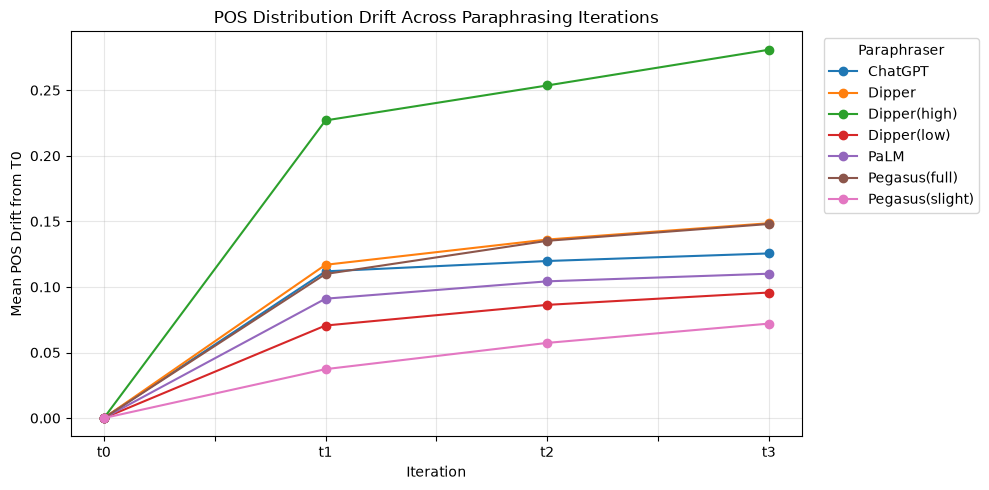

In [11]:
plot_df = pos_summary.pivot(
    index="stage",
    columns="paraphraser",
    values="pos_drift"
)

plot_df = plot_df.reindex(["t0", "t1", "t2", "t3"])

ax = plot_df.plot(
    marker="o",
    figsize=(10, 5)
)

ax.set_title("POS Distribution Drift Across Paraphrasing Iterations")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean POS Drift from T0")
ax.grid(alpha=0.3)

plt.legend(
    title="Paraphraser",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### Summary:
The results show that average POS distribution drift increases from T0 to T3 for all seven paraphrasers. Dipper(high) produces the largest changes (0.281 at T3), while Pegasus(slight) produces the smallest changes (0.072). Most changes occur during the first paraphrasing iteration, followed by smaller increases in subsequent iterations. This suggests that repeated paraphrasing gradually changes the grammatical structure of the original text.

## 4. Dependency Depth Analysis

The two tables measure different things:
- Mean absolute change: How much dependency depth changes, regardless of direction.
- Mean signed change: Whether dependency depth tends to increase or decrease.

In [12]:
# Get original T0 dependency depth
t0_depth = df[df["stage"] == "t0"][
    id_cols + ["dependency_depth"]
].rename(columns={
    "dependency_depth": "depth_t0"
})

# Match each iteration to its original T0
depth_paired = df[
    id_cols + ["stage", "dependency_depth"]
].merge(
    t0_depth,
    on=id_cols,
    validate="many_to_one"
)

# Calculate signed and absolute changes
depth_paired["depth_change"] = (
    depth_paired["dependency_depth"] -
    depth_paired["depth_t0"]
)

depth_paired["abs_depth_change"] = (
    depth_paired["depth_change"].abs()
)

# Summarize by paraphraser and iteration
depth_summary = (
    depth_paired.groupby(["paraphraser", "stage"])
    .agg(
        mean_signed_change=("depth_change", "mean"),
        mean_absolute_change=("abs_depth_change", "mean")
    )
    .reset_index()
)

print("Mean absolute dependency-depth change:")
display(
    depth_summary.pivot(
        index="paraphraser",
        columns="stage",
        values="mean_absolute_change"
    ).round(3)
)

print("Mean signed dependency-depth change:")
display(
    depth_summary.pivot(
        index="paraphraser",
        columns="stage",
        values="mean_signed_change"
    ).round(3)
)

Mean absolute dependency-depth change:


stage,t0,t1,t2,t3
paraphraser,,,,
ChatGPT,0.0,0.894,0.957,1.000
Dipper,0.0,0.829,0.932,1.025
Dipper(high),0.0,1.564,1.796,1.963
Dipper(low),0.0,0.585,0.701,0.867
PaLM,0.0,0.717,0.807,0.862
Pegasus(full),0.0,0.785,1.150,1.337
Pegasus(slight),0.0,0.282,0.441,0.565


Mean signed dependency-depth change:


stage,t0,t1,t2,t3
paraphraser,,,,
ChatGPT,0.0,0.275,0.312,0.349
Dipper,0.0,-0.170,-0.264,-0.330
Dipper(high),0.0,-0.209,-0.338,-0.518
Dipper(low),0.0,-0.143,-0.141,-0.049
PaLM,0.0,0.036,0.079,0.102
Pegasus(full),0.0,-0.631,-1.051,-1.246
Pegasus(slight),0.0,-0.174,-0.314,-0.442


## 5. Dependency Depth Visualization

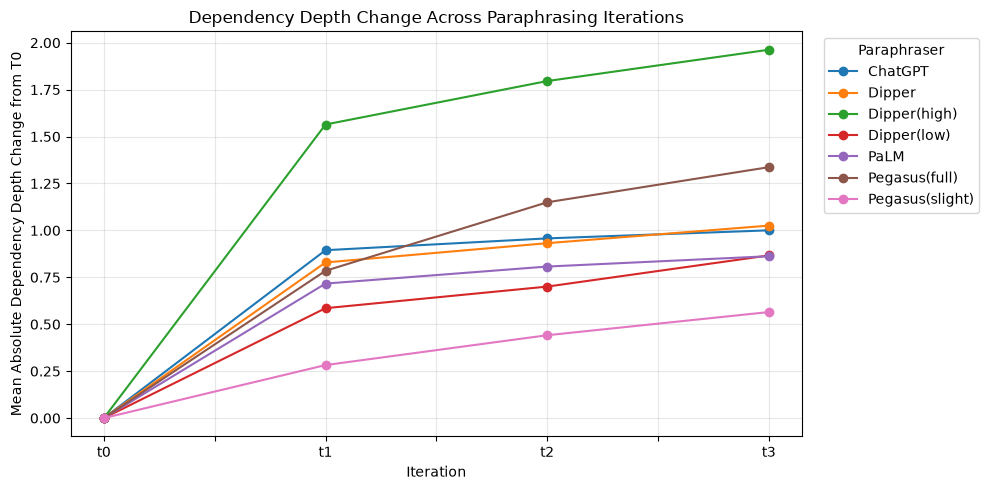

In [13]:
plot_depth = depth_summary.pivot(
    index="stage",
    columns="paraphraser",
    values="mean_absolute_change"
)

plot_depth = plot_depth.reindex(["t0", "t1", "t2", "t3"])

ax = plot_depth.plot(
    marker="o",
    figsize=(10, 5)
)

ax.set_title(
    "Dependency Depth Change Across Paraphrasing Iterations"
)
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean Absolute Dependency Depth Change from T0")
ax.grid(alpha=0.3)

plt.legend(
    title="Paraphraser",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### Summary
The results show that mean absolute dependency-depth changes increase from T0 to T3 for all seven paraphrasers, indicating progressive changes in sentence structure. Dipper(high) produces the largest absolute change (1.963 at T3), while Pegasus(slight) produces the smallest (0.565). However, signed changes show different trends. ChatGPT slightly increases dependency depth (+0.349), while Pegasus(full) substantially decreases it (-1.246). This suggests that repeated paraphrasing changes syntactic structure, but the direction and magnitude depend on the paraphraser.

## 6. Human vs. LLM Linguistic Drift

In [14]:
# POS drift by original source group
pos_group_summary = (
    paired.groupby(["source_group", "stage"])["pos_drift"]
    .mean()
    .reset_index()
)

# Dependency-depth change by original source group
depth_group_summary = (
    depth_paired.merge(
        df[id_cols + ["stage", "source_group"]],
        on=id_cols + ["stage"],
        validate="one_to_one"
    )
    .groupby(["source_group", "stage"])
    .agg(
        mean_abs_depth_change=("abs_depth_change", "mean"),
        mean_signed_depth_change=("depth_change", "mean")
    )
    .reset_index()
)

print("POS drift by source group:")
display(
    pos_group_summary.pivot(
        index="source_group",
        columns="stage",
        values="pos_drift"
    ).round(3)
)

print("Absolute dependency-depth change by source group:")
display(
    depth_group_summary.pivot(
        index="source_group",
        columns="stage",
        values="mean_abs_depth_change"
    ).round(3)
)

POS drift by source group:


stage,t0,t1,t2,t3
source_group,,,,
Human,0.0,0.105,0.122,0.135
LLM,0.0,0.110,0.129,0.142


Absolute dependency-depth change by source group:


stage,t0,t1,t2,t3
source_group,,,,
Human,0.0,0.735,0.896,0.982
LLM,0.0,0.823,0.986,1.113


##### Summary
Both Human and LLM source texts show increasing linguistic drift across paraphrasing iterations. At T3, LLM texts have slightly higher POS drift (0.142 vs. 0.135) and absolute dependency-depth change (1.113 vs. 0.982). This suggests that both groups experience progressive changes in writing style, with somewhat larger average changes for LLM texts. However, differences in dataset composition and sample sizes should be considered.

## 7. Human vs. LLM Comparison by Dataset and Paraphraser

In [15]:
# Add source-group labels to dependency-depth results
depth_labeled = depth_paired.merge(
    df[id_cols + ["stage", "source_group"]],
    on=id_cols + ["stage"],
    validate="one_to_one"
)

def compare_source_groups(data, metric):
    # Calculate group means within each dataset and paraphraser
    grouped = (
        data.groupby(
            ["dataset", "paraphraser", "stage", "source_group"]
        )[metric]
        .mean()
        .unstack("source_group")
        .dropna(subset=["Human", "LLM"])
        .reset_index()
    )

    grouped["difference"] = grouped["LLM"] - grouped["Human"]

    # Give each dataset-paraphraser combination equal weight
    return (
        grouped.groupby("stage")
        .agg(
            combinations=("difference", "size"),
            human_mean=("Human", "mean"),
            llm_mean=("LLM", "mean"),
            llm_minus_human=("difference", "mean")
        )
        .round(3)
    )


print("POS drift comparison:")
display(compare_source_groups(paired, "pos_drift"))

print("Dependency-depth comparison:")
display(compare_source_groups(depth_labeled, "abs_depth_change"))

POS drift comparison:


,combinations,human_mean,llm_mean,llm_minus_human
stage,,,,
t0,49,0.000,0.000,0.000
t1,49,0.103,0.109,0.006
t2,49,0.120,0.127,0.007
t3,49,0.132,0.140,0.008


Dependency-depth comparison:


,combinations,human_mean,llm_mean,llm_minus_human
stage,,,,
t0,49,0.000,0.000,0.000
t1,49,0.730,0.818,0.088
t2,49,0.889,0.981,0.092
t3,49,0.973,1.106,0.133


##### Summary
After giving equal weight to the 49 dataset–paraphraser combinations, LLM source texts still show slightly larger average linguistic changes than Human texts. At T3, mean POS drift is 0.140 for LLM texts and 0.132 for Human texts. Mean absolute dependency-depth change is also higher for LLM texts (1.106 vs. 0.973). These results suggest that both groups experience progressive stylistic changes, with slightly larger changes in LLM texts. However, differences in sample sizes and text characteristics may still influence the results.

## 8. Export RQ1 Results

In [16]:
# Separate output directories for Update 2
results_dir = PROJECT_ROOT / "data/results/update2"
figures_dir = PROJECT_ROOT / "figures/update2"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save CSV results
pos_summary.to_csv(
    results_dir / "pos_drift_summary.csv", index=False
)

depth_summary.to_csv(
    results_dir / "dependency_depth_summary.csv", index=False
)

compare_source_groups(
    paired, "pos_drift"
).to_csv(results_dir / "pos_human_llm_comparison.csv")

compare_source_groups(
    depth_labeled, "abs_depth_change"
).to_csv(results_dir / "depth_human_llm_comparison.csv")

# Save POS drift figure
ax = plot_df.plot(marker="o", figsize=(10, 5))
ax.set_title("POS Distribution Drift Across Paraphrasing Iterations")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean POS Drift from T0")
ax.grid(alpha=0.3)
ax.legend(title="Paraphraser", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig(figures_dir / "pos_drift.png", dpi=300, bbox_inches="tight")
plt.close()

# Save dependency-depth figure
ax = plot_depth.plot(marker="o", figsize=(10, 5))
ax.set_title("Dependency Depth Change Across Paraphrasing Iterations")
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean Absolute Dependency Depth Change from T0")
ax.grid(alpha=0.3)
ax.legend(title="Paraphraser", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig(figures_dir / "dependency_depth.png", dpi=300, bbox_inches="tight")
plt.close()

print("Results saved to:", results_dir)
print("Figures saved to:", figures_dir)

Results saved to: /Users/chuweicai/Desktop/6120/Ship-of-Theseus-Paraphrased-Corpus-CS6120-Team4/data/results/update2
Figures saved to: /Users/chuweicai/Desktop/6120/Ship-of-Theseus-Paraphrased-Corpus-CS6120-Team4/figures/update2
